# Preparação do Spotify Music Features Dataset para recomendação por sentimentos

Este notebook prepara o [Spotify Music Features Dataset](https://www.kaggle.com/datasets/amith1707/spotify-music-features-dataset/), usando o **arquivo completo com popularidade ≥60**, sem filtro de gêneros.

Seguimos a mesma estrutura do notebook original: diagnóstico, limpeza, gráficos, transformação dos eixos, quadrantes e exportação.

No plano emocional, **valence** é o eixo horizontal e **energy** aproxima a ativação no eixo vertical. Ambos são convertidos de `[0,1]` para `[-1,1]` com `2*x−1`. Os quadrantes são interpretações auxiliares, não emoções avaliadas por pessoas.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
MIN_POPULARITY = 60

raw_relative = Path("raw/spotify-music-features-v1/data/full/spotify_full.csv")
data_candidates = [Path("../data"), Path("data"), Path("music-mood-backend/data")]
DATA_DIR = next((p.resolve() for p in data_candidates if (p / raw_relative).exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Não foi possível localizar spotify_full.csv na pasta data/raw.")

RAW_PATH = DATA_DIR / raw_relative
OUTPUT_PATH = DATA_DIR / "processed/spotify-music-features-filtered.csv"
print(f"Entrada: {RAW_PATH}")
print(f"Saída: {OUTPUT_PATH}")

Entrada: /home/josea/project-tcc/music-mood-backend/data/raw/spotify-music-features-v1/data/full/spotify_full.csv
Saída: /home/josea/project-tcc/music-mood-backend/data/processed/spotify-music-features-filtered.csv


## 1. Carregamento e diagnóstico inicial

Lemos apenas a identificação, a popularidade e os atributos de áudio usados nesta análise. `spotify_id` contém o ID de 22 caracteres; a coluna `track_id` da fonte contém a URI completa. Renomeamos os campos para os nomes utilizados no projeto.

In [2]:
columns = [
    "spotify_id", "title", "track_artist", "track_popularity",
    "duration_ms", "has_audio_features", "popularity_imputed_aug",
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo",
]
raw_df = pd.read_csv(RAW_PATH, usecols=columns).rename(columns={
    "spotify_id": "track_id", "title": "track_name",
    "track_artist": "artists", "track_popularity": "popularity",
})
print(f"Entrada: {len(raw_df):,} linhas; {len(raw_df.columns)} colunas selecionadas")
raw_df.head()

Entrada: 1,182,354 linhas; 16 colunas selecionadas


,track_id,track_name,artists,duration_ms,has_audio_features,energy,valence,danceability,acousticness,instrumentalness,speechiness,liveness,loudness,tempo,popularity,popularity_imputed_aug
0,0yLdNVWF3Srea0uzk55zFn,Flowers,Miley Cyrus,200455,True,0.681,0.646,0.707,0.06320,0.000005,0.0668,0.0322,-4.325,117.999,100,False
1,0sf12qNH5qcw8qpgymFOqD,Blinding Lights,The Weeknd,201573,True,0.796,0.345,0.513,0.00147,0.000209,0.0629,0.0938,-4.075,171.017,98,False
2,21jGcNKet2qwijlDFuPiPb,Circles,Post Malone,215280,True,0.762,0.553,0.695,0.19200,0.002440,0.0395,0.0863,-3.497,120.042,98,False
3,2b8fOow8UzyDFAE27YhOZM,Memories,Maroon 5,189486,True,0.320,0.575,0.764,0.83700,0.000000,0.0546,0.0822,-7.209,91.019,98,False
4,7k4t7uLgtOxPwTpFmtJNTY,Tusa,KAROL G,200960,True,0.715,0.574,0.803,0.29500,0.000134,0.2980,0.0574,-3.280,101.085,98,False


In [3]:
diagnostic = pd.DataFrame({
    "tipo": raw_df.dtypes.astype(str),
    "ausentes": raw_df.isna().sum(),
    "percentual_ausente": raw_df.isna().mean().mul(100).round(3),
    "unicos": raw_df.nunique(dropna=False),
})
diagnostic

,tipo,ausentes,percentual_ausente,unicos
track_id,str,0,0.000,1182354
track_name,str,5,0.000,891595
artists,str,19,0.002,69415
duration_ms,int64,0,0.000,259361
has_audio_features,bool,0,0.000,1
energy,float64,0,0.000,3117
valence,float64,0,0.000,2177
danceability,float64,0,0.000,1364
acousticness,float64,0,0.000,5399
instrumentalness,float64,0,0.000,5403


In [4]:
print(f"Linhas completamente duplicadas: {raw_df.duplicated().sum():,}")
print(f"Registros excedentes com track_id repetido: {raw_df.duplicated('track_id').sum():,}")
print(f"Faixas unicas por track_id: {raw_df['track_id'].nunique():,}")

Linhas completamente duplicadas: 0
Registros excedentes com track_id repetido: 0
Faixas unicas por track_id: 1,182,354


## 2. Limpeza e filtro de popularidade

Mantemos as mesmas regras do catálogo completo avaliado no experimento:

1. popularidade ≥60, dentro de [0,100] e não imputada;
2. ID Spotify válido, título e artista preenchidos;
3. áudio disponível, valence/energy em [0,1] e duração positiva;
4. uma linha por ID, priorizando maior popularidade.

Não filtramos gêneros nem exigimos álbum ou assinatura de tempo. A deduplicação por artista/título, aplicada durante a recomendação, permanece fora da preparação do catálogo.

In [5]:
df = raw_df.copy()
audit = [("Dataset original", len(df))]

df = df.loc[
    df["popularity"].between(MIN_POPULARITY, 100)
    & df["popularity_imputed_aug"].eq(False)
].copy()
audit.append(("Após filtrar popularidade observada ≥60", len(df)))

required_text = ["track_id", "track_name", "artists"]
valid_text = df["track_id"].astype("string").str.fullmatch(r"[A-Za-z0-9]{22}", na=False)
for column in required_text:
    valid_text &= df[column].notna() & df[column].astype("string").str.strip().ne("")
df = df.loc[valid_text].copy()
audit.append(("Após validar identificação", len(df)))

valid_audio = (
    df[["valence", "energy"]].ge(0).all(axis=1)
    & df[["valence", "energy"]].le(1).all(axis=1)
    & df["has_audio_features"].eq(True)
    & df["duration_ms"].gt(0)
)
df = df.loc[valid_audio].copy()
audit.append(("Após validar áudio e duração", len(df)))

df = df.sort_values(["popularity", "track_id"], ascending=[False, True])
df = df.drop_duplicates("track_id").reset_index(drop=True)
audit.append(("Após deduplicar ID", len(df)))

audit_df = pd.DataFrame(audit, columns=["etapa", "numero_de_musicas"])
audit_df["removidas_na_etapa"] = -audit_df["numero_de_musicas"].diff().fillna(0).astype(int)
audit_df

,etapa,numero_de_musicas,removidas_na_etapa
0,Dataset original,1182354,0
1,Após filtrar popularidade observada ≥60,19751,1162603
2,Após validar identificação,19751,0
3,Após validar áudio e duração,19751,0
4,Após deduplicar ID,19751,0


In [6]:
assert df["track_id"].is_unique
assert not df[required_text].isna().any().any()
assert df["popularity"].between(MIN_POPULARITY, 100).all()
assert df[["energy", "valence"]].ge(0).all().all()
assert df[["energy", "valence"]].le(1).all().all()
print(f"Dataset limpo: {len(df):,} músicas.")

Dataset limpo: 19,751 músicas.


## 3. Gráficos após a filtragem

A distribuição de popularidade descreve o catálogo selecionado. A matriz de correlação mostra as relações entre os atributos de áudio.

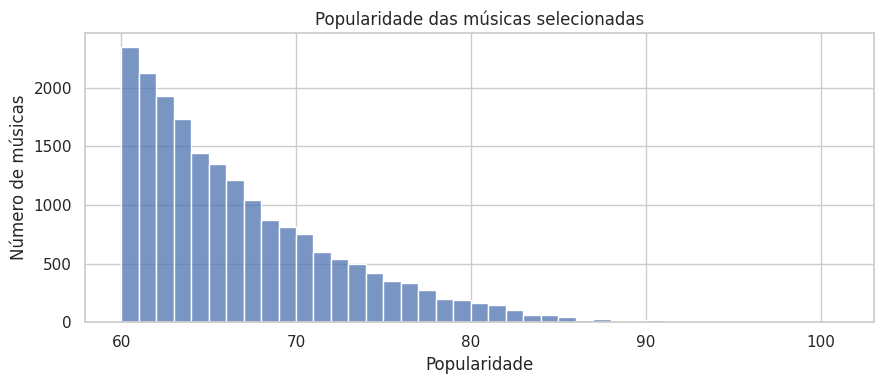

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df["popularity"], bins=np.arange(MIN_POPULARITY, 102), ax=ax)
ax.set(title="Popularidade das músicas selecionadas", xlabel="Popularidade", ylabel="Número de músicas")
plt.tight_layout()
plt.show()

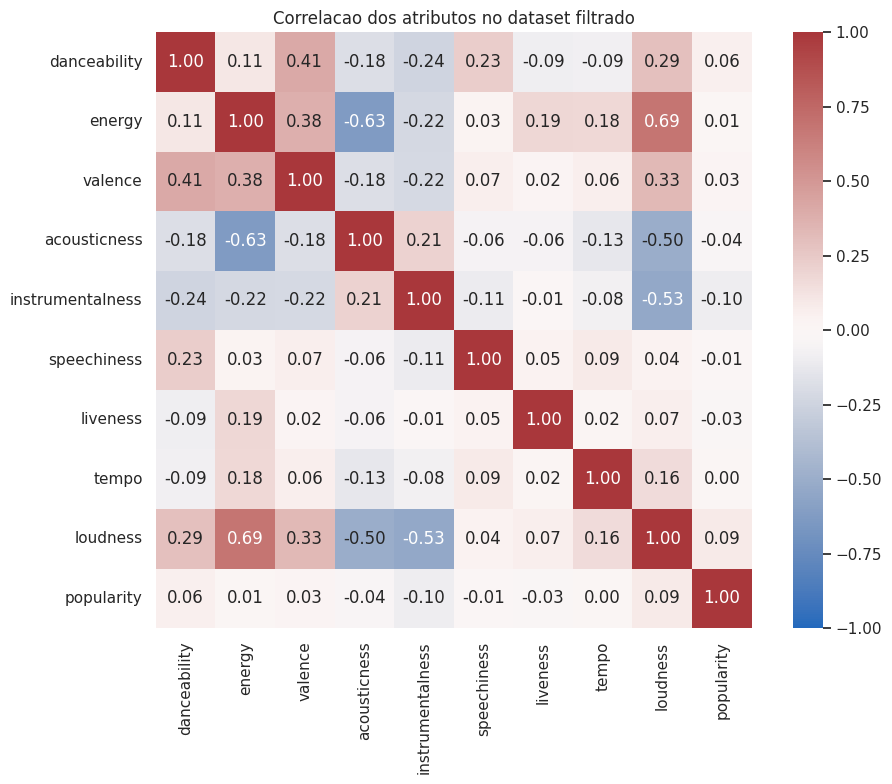

In [8]:
features_for_correlation = [
    "danceability", "energy", "valence", "acousticness",
    "instrumentalness", "speechiness", "liveness", "tempo",
    "loudness", "popularity",
]

plt.figure(figsize=(10, 8))
sns.heatmap(
    df[features_for_correlation].corr(),
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
)
plt.title("Correlacao dos atributos no dataset filtrado")
plt.tight_layout()
plt.show()

## 4. Transformacao para o plano emocional de Russell

A transformacao linear abaixo preserva a ordem e a distribuicao dos dados, apenas centralizando a escala em zero:

$$x_{novo} = 2x - 1$$

Depois dela, `-1` representa baixa energia ou valencia negativa, `0` o ponto neutro e `1` alta energia ou valencia positiva.

In [9]:
original_energy = df["energy"].copy()
original_valence = df["valence"].copy()

df["energy"] = 2 * df["energy"] - 1
df["valence"] = 2 * df["valence"] - 1

assert df[["energy", "valence"]].ge(-1).all().all()
assert df[["energy", "valence"]].le(1).all().all()
assert np.allclose(df["energy"], 2 * original_energy - 1)
assert np.allclose(df["valence"], 2 * original_valence - 1)

df[["track_name", "artists", "energy", "valence"]].head()

,track_name,artists,energy,valence
0,Flowers,Miley Cyrus,0.362,0.292
1,The Box,Roddy Ricch,0.172,0.284
2,Blinding Lights,The Weeknd,0.592,-0.310
3,Circles,Post Malone,0.524,0.106
4,Memories,Maroon 5,-0.360,0.150


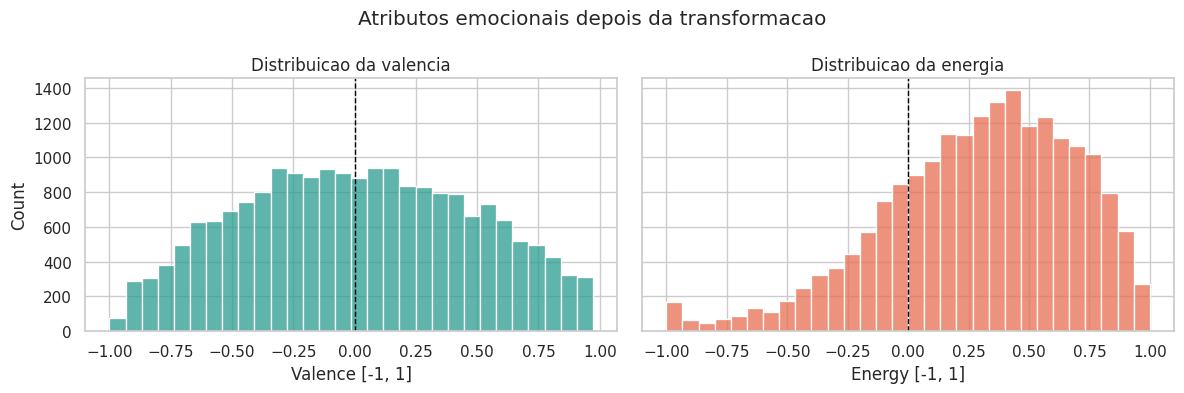

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.histplot(df["valence"], bins=30, kde=False, ax=axes[0], color="#2a9d8f")
sns.histplot(df["energy"], bins=30, kde=False, ax=axes[1], color="#e76f51")
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set(title="Distribuicao da valencia", xlabel="Valence [-1, 1]")
axes[1].set(title="Distribuicao da energia", xlabel="Energy [-1, 1]")
fig.suptitle("Atributos emocionais depois da transformacao")
plt.tight_layout()
plt.show()

### 4.1 Musicas no plano cartesiano

Cada ponto representa uma musica. A transparencia ajuda a revelar concentracoes sem esconder completamente observacoes individuais. Os nomes dos quadrantes sao interpretacoes praticas do modelo, nao rotulos fornecidos pelo Spotify.

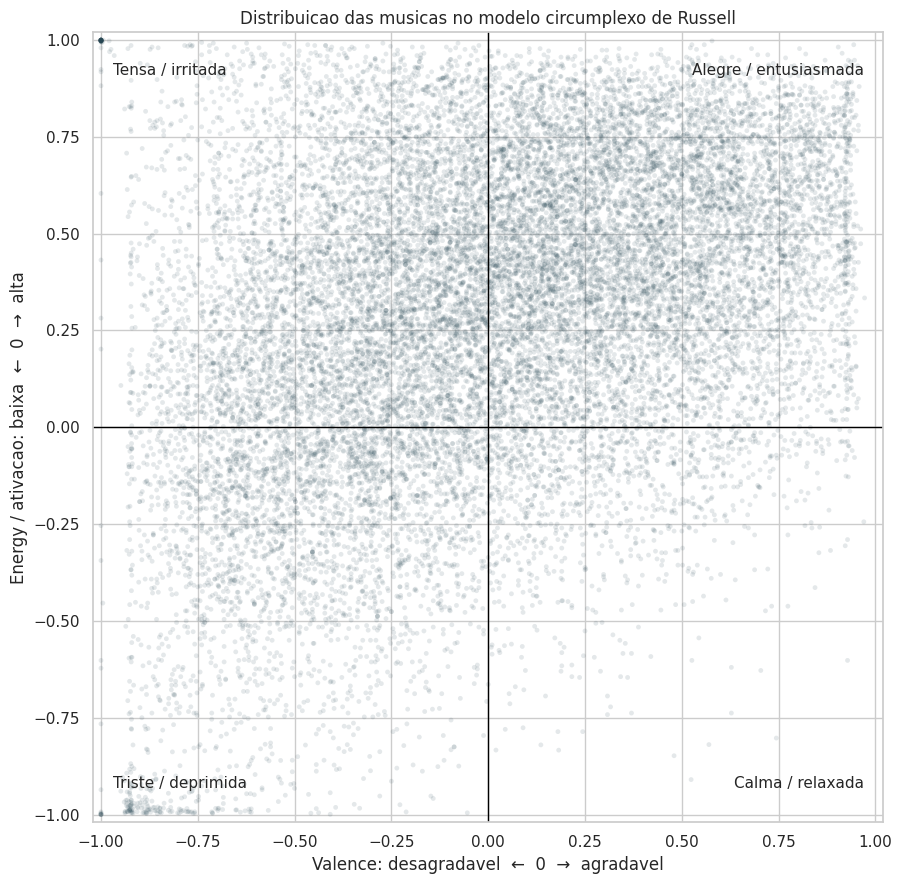

In [11]:
fig, ax = plt.subplots(figsize=(10, 9))
ax.scatter(
    df["valence"],
    df["energy"],
    s=12,
    alpha=0.12,
    color="#264653",
    edgecolors="none",
    rasterized=True,
)
ax.axhline(0, color="black", linewidth=1)
ax.axvline(0, color="black", linewidth=1)
ax.set(
    xlim=(-1.02, 1.02),
    ylim=(-1.02, 1.02),
    xlabel="Valence: desagradavel  ←  0  →  agradavel",
    ylabel="Energy / ativacao: baixa  ←  0  →  alta",
    title="Distribuicao das musicas no modelo circumplexo de Russell",
)
ax.text(0.97, 0.94, "Alegre / entusiasmada", ha="right", va="top", fontsize=11)
ax.text(-0.97, 0.94, "Tensa / irritada", ha="left", va="top", fontsize=11)
ax.text(-0.97, -0.94, "Triste / deprimida", ha="left", va="bottom", fontsize=11)
ax.text(0.97, -0.94, "Calma / relaxada", ha="right", va="bottom", fontsize=11)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

### 4.2 Densidade emocional

O grafico hexagonal complementa o grafico de pontos: cores mais intensas indicam regioes com maior quantidade de musicas.

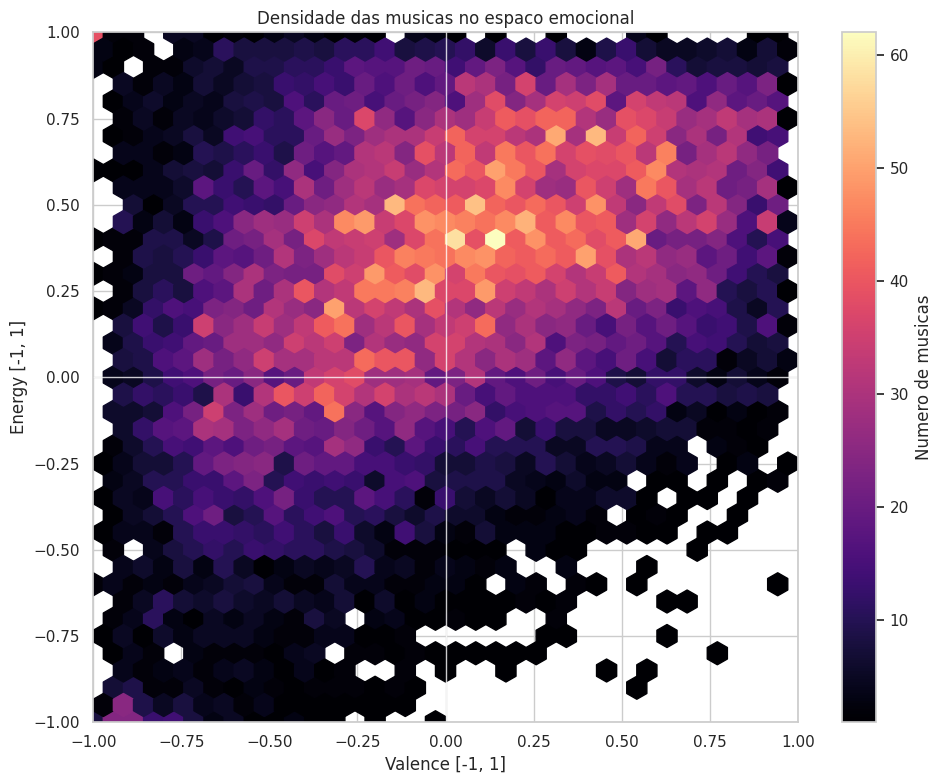

In [12]:
fig, ax = plt.subplots(figsize=(10, 8))
hexbin = ax.hexbin(
    df["valence"],
    df["energy"],
    gridsize=35,
    extent=(-1, 1, -1, 1),
    mincnt=1,
    cmap="magma",
)
ax.axhline(0, color="white", linewidth=1, alpha=0.8)
ax.axvline(0, color="white", linewidth=1, alpha=0.8)
ax.set(
    xlim=(-1, 1), ylim=(-1, 1),
    xlabel="Valence [-1, 1]", ylabel="Energy [-1, 1]",
    title="Densidade das musicas no espaco emocional",
)
fig.colorbar(hexbin, ax=ax, label="Numero de musicas")
plt.tight_layout()
plt.show()

## 5. Quadrantes emocionais

O quadrante e salvo como informacao auxiliar e pode ser usado para diagnostico, filtros ou explicacao das recomendacoes. Para calcular proximidade entre uma emocao e uma musica, os valores continuos de `energy` e `valence` devem continuar sendo priorizados.

In [13]:
conditions = [
    (df["energy"] >= 0) & (df["valence"] >= 0),
    (df["energy"] >= 0) & (df["valence"] < 0),
    (df["energy"] < 0) & (df["valence"] < 0),
    (df["energy"] < 0) & (df["valence"] >= 0),
]
labels = [
    "alegre_entusiasmada",
    "tensa_irritada",
    "triste_deprimida",
    "calma_relaxada",
]
df["emotion_quadrant"] = np.select(conditions, labels, default="neutra")

quadrant_distribution = (
    df["emotion_quadrant"]
    .value_counts()
    .rename_axis("quadrante")
    .reset_index(name="musicas")
)
quadrant_distribution["percentual"] = (
    quadrant_distribution["musicas"].div(len(df)).mul(100).round(2)
)
quadrant_distribution

,quadrante,musicas,percentual
0,alegre_entusiasmada,8890,45.01
1,tensa_irritada,6483,32.82
2,triste_deprimida,3307,16.74
3,calma_relaxada,1071,5.42


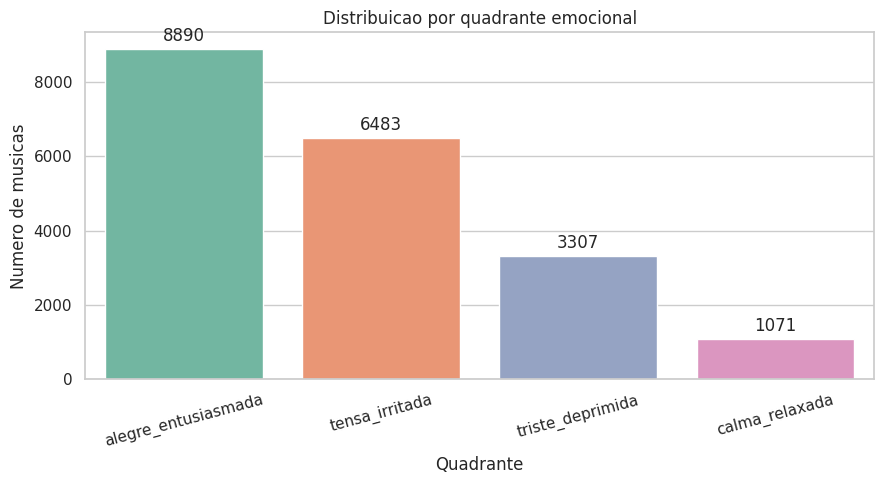

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=quadrant_distribution,
    x="quadrante",
    y="musicas",
    hue="quadrante",
    palette="Set2",
    legend=False,
    ax=ax,
)
ax.set(title="Distribuicao por quadrante emocional", xlabel="Quadrante", ylabel="Numero de musicas")
ax.tick_params(axis="x", rotation=15)
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()

## 6. Exportação

Salvamos um CSV com uma linha por ID, popularidade ≥60, atributos de áudio e quadrante auxiliar. `energy` e `valence` ficam na escala `[-1,1]`. A saída é `data/processed/spotify-music-features-filtered.csv`.

In [15]:
output_columns = [
    "track_id", "artists", "track_name", "popularity", "duration_ms",
    "danceability", "energy", "loudness", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "emotion_quadrant",
]
final_df = df[output_columns].sort_values(
    ["artists", "track_name", "track_id"]
).reset_index(drop=True)

assert final_df["track_id"].is_unique
assert final_df["popularity"].between(MIN_POPULARITY, 100).all()
assert final_df[["energy", "valence"]].ge(-1).all().all()
assert final_df[["energy", "valence"]].le(1).all().all()
assert not final_df[required_text + ["energy", "valence", "popularity"]].isna().any().any()

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
final_df.to_csv(OUTPUT_PATH, index=False)
print(f"Arquivo salvo: {OUTPUT_PATH}")
print(f"Dimensões finais: {len(final_df):,} músicas × {len(final_df.columns)} colunas")
final_df.head()

Arquivo salvo: /home/josea/project-tcc/music-mood-backend/data/processed/spotify-music-features-filtered.csv
Dimensões finais: 19,751 músicas × 15 colunas


,track_id,artists,track_name,popularity,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,emotion_quadrant
0,3YFnfm9z8RmPFIZ7C16u4e,$NOT,Doja,62,171453,0.753,0.554,-5.701,0.3200,0.0725,0.000714,0.1250,0.338,157.148,alegre_entusiasmada
1,0j8ppsOOawdPCJnSTcXgOy,$NOT,GOSHA,71,120000,0.847,-0.104,-10.140,0.4160,0.8100,0.000013,0.3250,-0.024,79.975,triste_deprimida
2,706ZrLifsm0nwlucKr4kQg,$NOT,Like Me (feat. iann dior),64,167147,0.902,-0.076,-7.945,0.0979,0.1900,0.000002,0.0940,0.292,103.984,calma_relaxada
3,3PXi72ZtSqx1PZc40KS0Qj,$NOT,Mean,60,125853,0.844,0.440,-7.418,0.3000,0.1690,0.000000,0.0797,0.262,99.917,alegre_entusiasmada
4,3oGbHF3Kdwf3AsRCbBjUxu,$NOT,Moon & Stars (feat. Maggie Lindemann),65,187587,0.713,-0.060,-8.698,0.0864,0.6060,0.000013,0.3060,-0.835,84.518,triste_deprimida
